In [14]:
# Import the sys module, which gives us information about Python
import sys

# Print the Python version so we know Python is working
print(sys.version)

3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]


In [15]:
# Install the libraries we need for this lab.
# The "%pip" command installs packages into the same Python that runs this notebook.
%pip install opencv-python numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [16]:
# os lets Python look inside folders on your computer
import os

# The name of the folder that holds all the shape folders.
# This works because your notebook is saved next to "selected_dataset".
dataset_folder = "selected_dataset"

# Get the names of everything inside the dataset folder (circle, decagon, ...)
# sorted() puts them in alphabetical order
class_names = sorted(os.listdir(dataset_folder))

# Show how many shape folders we found (we expect 17)
print("Number of shape folders:", len(class_names))
print()

# Go through each shape folder one by one
for name in class_names:
    # Build the full path to this shape folder, e.g. selected_dataset/circle
    folder_path = os.path.join(dataset_folder, name)

    # Count how many files are inside it
    count = len(os.listdir(folder_path))

    # Print the shape name and its image count
    print(name, ":", count, "images")

Number of shape folders: 18

.DS_Store : 0 images
circle : 300 images
decagon : 300 images
heptagon : 300 images
hexagon : 300 images
kite : 300 images
nonagon : 300 images
octagon : 300 images
oval : 300 images
parallelogram : 300 images
pentagon : 300 images
rectangle : 300 images
rhombus : 300 images
semicircle : 300 images
square : 300 images
star : 300 images
trapezoid : 300 images
triangle : 300 images


Number of shapes: 17
File: circle_10318.png
Image size: (224, 224, 3)


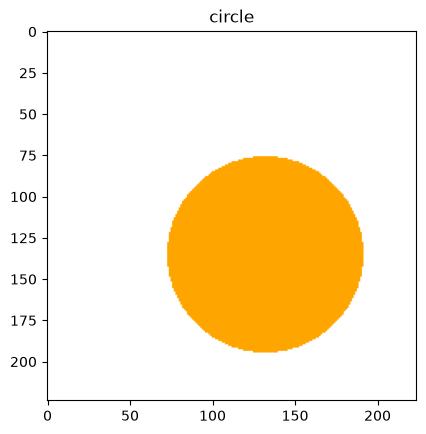

In [17]:
# cv2 is OpenCV, the library that reads images
import cv2
# matplotlib lets us display an image inside the notebook
import matplotlib.pyplot as plt

# Keep only real folders, so hidden files like .DS_Store are skipped
class_names = [name for name in sorted(os.listdir(dataset_folder))
               if os.path.isdir(os.path.join(dataset_folder, name))
               and not name.startswith(".")]

# Check that we now have exactly 17 shapes
print("Number of shapes:", len(class_names))

# Pick the first image inside the "circle" folder
circle_folder = os.path.join(dataset_folder, "circle")
first_file = sorted(os.listdir(circle_folder))[0]
image_path = os.path.join(circle_folder, first_file)

# Read the image from the file into a numpy array
image = cv2.imread(image_path)

# Print the file name and the size of the image
# (we expect something like (224, 224, 3) = height, width, 3 color channels)
print("File:", first_file)
print("Image size:", image.shape)

# OpenCV reads colors as BGR, but matplotlib expects RGB, so we convert
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("circle")
plt.show()

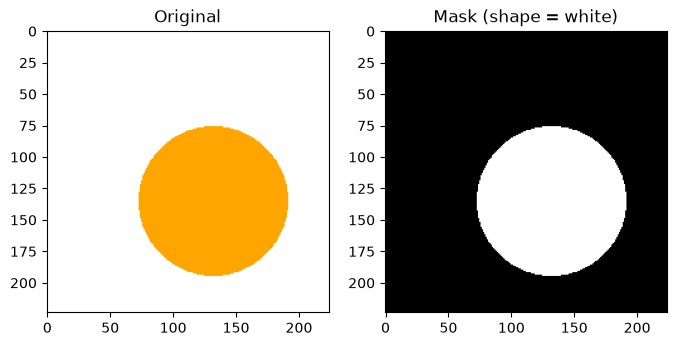

In [18]:
# Convert the color image to grayscale (one number per pixel, 0=black, 255=white)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Make a black-and-white "mask":
# pixels darker than 250 (the shape) become 255 (white)
# pixels that are almost white (the background) become 0 (black)
# THRESH_BINARY_INV flips it so the SHAPE is white
_, mask = cv2.threshold(gray, 250, 255, cv2.THRESH_BINARY_INV)

# Show the original and the mask side by side
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Mask (shape = white)")

plt.show()

In [19]:
import numpy as np

# Find the outlines (contours) of all white areas in the mask
# RETR_EXTERNAL = only the outer outline, CHAIN_APPROX_NONE = keep every point
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

# Our images have one shape, so take the biggest contour
contour = max(contours, key=cv2.contourArea)

# FEATURE 1: area = how many pixels the shape covers
area = cv2.contourArea(contour)

# FEATURE 2: perimeter = the length of the outline
perimeter = cv2.arcLength(contour, True)

# FEATURE 3: circularity = how close the shape is to a perfect circle
# A perfect circle gives 1.0. Shapes with corners give smaller numbers.
circularity = 4 * np.pi * area / (perimeter ** 2)

# FEATURE 4: number of corners
# approxPolyDP simplifies the outline into straight lines.
# The number of points left is roughly the number of corners.
approx = cv2.approxPolyDP(contour, 0.02 * perimeter, True)
corners = len(approx)

# Print all four features
print("Area:", area)
print("Perimeter:", round(perimeter, 2))
print("Circularity:", round(circularity, 3))
print("Corners:", corners)

Area: 10922.0
Perimeter: 389.99
Circularity: 0.902
Corners: 8


In [20]:
# The names of our features, in the same order the function returns them
feature_names = [
    "area_ratio",     # how much of the image the shape covers (0 to 1)
    "circularity",    # 1.0 = perfect circle, lower = more corners
    "corners_2",      # corner count using a fine outline simplification
    "corners_4",      # corner count using a coarser outline simplification
    "aspect_ratio",   # long side / short side of the tightest rotated box
    "extent",         # shape area / tightest rotated box area
    "solidity",       # shape area / convex hull area (detects dents, like in a star)
    "hu_1", "hu_2", "hu_3", "hu_4", "hu_5", "hu_6", "hu_7"  # Hu moments (shape signature)
]

def extract_features(img):
    """Takes a color image and returns a list of numbers describing the shape in it."""

    # 1. Make the black-and-white mask (shape = white), same as Step 9
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, mask = cv2.threshold(gray, 250, 255, cv2.THRESH_BINARY_INV)

    # 2. Find the outline and keep the biggest one
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contour = max(contours, key=cv2.contourArea)

    # 3. Basic measurements
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    # Area as a fraction of the whole image (224 x 224 pixels)
    area_ratio = area / (img.shape[0] * img.shape[1])

    # Circularity: 1.0 for a circle, smaller for shapes with corners
    circularity = 4 * np.pi * area / (perimeter ** 2)

    # 4. Corner counts at two different simplification levels
    corners_2 = len(cv2.approxPolyDP(contour, 0.02 * perimeter, True))
    corners_4 = len(cv2.approxPolyDP(contour, 0.04 * perimeter, True))

    # 5. Tightest rotated rectangle around the shape -> aspect ratio and extent
    (_, _), (w, h), _ = cv2.minAreaRect(contour)
    aspect_ratio = max(w, h) / max(min(w, h), 1e-6)   # always 1 or bigger
    extent = area / max(w * h, 1e-6)

    # 6. Solidity: shape area divided by the area of its convex hull
    hull = cv2.convexHull(contour)
    solidity = area / max(cv2.contourArea(hull), 1e-6)

    # 7. Hu moments: 7 numbers that stay the same when the shape moves, scales, or rotates
    hu = cv2.HuMoments(cv2.moments(contour)).flatten()
    # Use the absolute value and a safer tiny number (1e-12).
    # Now a "nearly zero" moment always becomes about 12, instead of jumping randomly.
    hu = -np.log10(np.abs(hu) + 1e-12)

    # Return everything as one list of numbers
    return [area_ratio, circularity, corners_2, corners_4,
            aspect_ratio, extent, solidity] + list(hu)

# Test the function on the circle image from Step 8
features = extract_features(image)
for name, value in zip(feature_names, features):
    print(name, ":", round(float(value), 4))

area_ratio : 0.2177
circularity : 0.9024
corners_2 : 8.0
corners_4 : 8.0
aspect_ratio : 1.0
extent : 0.7927
solidity : 0.9927
hu_1 : 0.7982
hu_2 : 12.0
hu_3 : 12.0
hu_4 : 12.0
hu_5 : 12.0
hu_6 : 12.0
hu_7 : 12.0


In [21]:
# X will hold the features of every image (one row per image)
# y will hold the correct shape name for every image
X = []
y = []

# Go through each of the 17 shapes
for class_name in class_names:
    folder_path = os.path.join(dataset_folder, class_name)

    # Go through every image file inside this shape's folder
    for file_name in sorted(os.listdir(folder_path)):
        file_path = os.path.join(folder_path, file_name)

        # Read the image from the file
        img = cv2.imread(file_path)

        # If OpenCV could not read the file, skip it
        if img is None:
            print("Could not read:", file_path)
            continue

        # Measure the shape and save the numbers and the label
        X.append(extract_features(img))
        y.append(class_name)

    # Show progress after each shape is finished
    print("Done:", class_name)

# Convert the lists into numpy arrays, which scikit-learn works with
X = np.array(X)
y = np.array(y)

# Check the sizes: we expect 5100 rows and 14 columns
print()
print("X shape:", X.shape)
print("y shape:", y.shape)

Done: circle
Done: decagon
Done: heptagon
Done: hexagon
Done: kite
Done: nonagon
Done: octagon
Done: oval
Done: parallelogram
Done: pentagon
Done: rectangle
Done: rhombus
Done: semicircle
Done: square
Done: star
Done: trapezoid
Done: triangle

X shape: (5100, 14)
y shape: (5100,)


In [22]:
# train_test_split divides our data into a training part and a testing part
from sklearn.model_selection import train_test_split
# DecisionTreeClassifier is our first model
from sklearn.tree import DecisionTreeClassifier
# accuracy_score measures what fraction of predictions were correct
from sklearn.metrics import accuracy_score

# Split: 80% for training, 20% for testing
# stratify=y keeps the same number of each shape in both parts
# random_state=42 makes the split the same every time you run it
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Show how many images are in each part
print("Training images:", len(X_train))
print("Testing images:", len(X_test))

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(random_state=42)

# Train the model: it learns the link between features (X_train) and shapes (y_train)
tree_model.fit(X_train, y_train)

# Ask the trained model to predict the shapes of the test images
tree_predictions = tree_model.predict(X_test)

# Compare the predictions to the correct answers
tree_accuracy = accuracy_score(y_test, tree_predictions)
print("Decision Tree accuracy:", round(tree_accuracy * 100, 2), "%")

Training images: 4080
Testing images: 1020
Decision Tree accuracy: 99.61 %


In [23]:
# Random Forest = many decision trees voting together
from sklearn.ensemble import RandomForestClassifier
# SVM = Support Vector Machine
from sklearn.svm import SVC
# StandardScaler puts all features on a similar scale
from sklearn.preprocessing import StandardScaler
# Pipeline chains the scaler and the model into one step
from sklearn.pipeline import make_pipeline

# Create the Random Forest with 100 trees
forest_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Create the SVM; it scales the features first, then classifies
svm_model = make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=42))

# Train both models on the training data
forest_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)

# Predict the shapes of the test images with each model
forest_predictions = forest_model.predict(X_test)
svm_predictions = svm_model.predict(X_test)

# Measure accuracy for each model
forest_accuracy = accuracy_score(y_test, forest_predictions)
svm_accuracy = accuracy_score(y_test, svm_predictions)

# Print the comparison of all three models
print("Decision Tree :", round(tree_accuracy * 100, 2), "%")
print("Random Forest :", round(forest_accuracy * 100, 2), "%")
print("SVM           :", round(svm_accuracy * 100, 2), "%")

Decision Tree : 99.61 %
Random Forest : 96.86 %
SVM           : 95.78 %


In [24]:
# This function lists every kind of mistake a model made,
# for example "square -> rhombus : 5" means 5 squares were wrongly predicted as rhombus
def show_confusions(model_name, predictions):
    print(model_name)

    # Count each (true shape, predicted shape) mistake
    mistakes = {}
    for true_shape, predicted_shape in zip(y_test, predictions):
        # Only look at the wrong predictions
        if true_shape != predicted_shape:
            key = (true_shape, predicted_shape)
            mistakes[key] = mistakes.get(key, 0) + 1

    # Print the most common mistakes first
    for (true_shape, predicted_shape), count in sorted(mistakes.items(), key=lambda item: -item[1]):
        print("  ", true_shape, "->", predicted_shape, ":", count)
    print()

# Show the mistakes for each of the three models
show_confusions("Decision Tree", tree_predictions)
show_confusions("Random Forest", forest_predictions)
show_confusions("SVM", svm_predictions)

Decision Tree
   decagon -> nonagon : 3
   rhombus -> square : 1

Random Forest
   square -> rhombus : 32

SVM
   square -> rhombus : 34
   decagon -> octagon : 4
   nonagon -> decagon : 4
   rhombus -> square : 1



# Lab Practice: Own Feature Extraction for ML

## Feature extraction method
Each 224x224 image was converted to grayscale and thresholded (pixels darker than 250 became the shape, the rest background). OpenCV found the shape's outer contour, and 14 numerical features were measured from it:
- area_ratio, circularity, extent, solidity, aspect_ratio (from the tightest rotated rectangle)
- corners_2 and corners_4 (corner counts from contour approximation at two levels)
- 7 Hu moments (log-scaled), which stay the same when a shape moves, scales, or rotates

Color was ignored because colors are random in this dataset. Most of the features (circularity, solidity, extent, aspect ratio, corner counts and Hu moments) do not change with position or rotation, and most also do not depend on size. The exception is area_ratio, which depends on how large the shape is.

## Setup
300 images per class x 17 classes = 5,100 images. The data was split 80% training (4,080) and 20% testing (1,020), stratified by class. SVM used StandardScaler on the features first.

## Results
| Model | Accuracy |
|---|---|
| Decision Tree | 99.61% |
| Random Forest | 96.86% |
| SVM | 95.78% |

## Discussion
All three models scored far above 70%. The Decision Tree performed best, with only 4 mistakes (decagon vs nonagon, one rhombus as square). The Random Forest and SVM made most of their mistakes on one pair: squares predicted as rhombuses (32 and 34 cases). A square is a special rhombus, and my features do not measure corner angles directly, so rotated squares and rhombuses look very similar. The SVM also mixed up octagon, nonagon and decagon, which look almost like circles at this image size. The Decision Tree likely won because it can use very exact thresholds on single features, while the other two smooth out small differences. A future improvement would be to add an angle-based feature, such as the angles between contour edges.